<a href="https://colab.research.google.com/github/snehabose-1826/ML_WCA_Project_GR7/blob/main/MY_ML_Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


**A. Data Loading**

In [ ]:
data = pd.read_csv("/content/Breast Cancer Wisconsin (Diagnostic) Data Set.csv")

Display

In [ ]:
data

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [ ]:
#Number of rows and columns
data.shape

(569, 33)

In [ ]:
#Column names
data.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

In [ ]:
#Data types
data.dtypes

,0
id,int64
diagnosis,object
radius_mean,float64
texture_mean,float64
perimeter_mean,float64
area_mean,float64
smoothness_mean,float64
compactness_mean,float64
concavity_mean,float64
concave points_mean,float64


In [ ]:
#First and last few records
data.head(10)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,NaN
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,NaN
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,NaN
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,NaN
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,NaN


In [ ]:
#First and last few records
data.tail(10)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
559,925291,B,11.51,23.93,74.52,403.5,0.09261,0.10210,0.11120,0.04105,...,37.16,82.28,474.2,0.12980,0.25170,0.3630,0.09653,0.2112,0.08732,NaN
560,925292,B,14.05,27.15,91.38,600.4,0.09929,0.11260,0.04462,0.04304,...,33.17,100.20,706.7,0.12410,0.22640,0.1326,0.10480,0.2250,0.08321,NaN
561,925311,B,11.20,29.37,70.67,386.0,0.07449,0.03558,0.00000,0.00000,...,38.30,75.19,439.6,0.09267,0.05494,0.0000,0.00000,0.1566,0.05905,NaN
562,925622,M,15.22,30.62,103.40,716.9,0.10480,0.20870,0.25500,0.09429,...,42.79,128.70,915.0,0.14170,0.79170,1.1700,0.23560,0.4089,0.14090,NaN
563,926125,M,20.92,25.09,143.00,1347.0,0.10990,0.22360,0.31740,0.14740,...,29.41,179.10,1819.0,0.14070,0.41860,0.6599,0.25420,0.2929,0.09873,NaN
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.22160,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.16280,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.14180,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.26500,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.00000,0.2871,0.07039,NaN


In [ ]:
data.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


B. Data Preprocessing

In [ ]:
#Identify and handle missing values.
data.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [ ]:
data = data.drop(columns=['id','Unnamed: 32'], errors='ignore')

In [ ]:
data

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [ ]:
# Detect and handle duplicate records.
data.duplicated().sum()
data[data.duplicated()]

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst


In [ ]:
# Identify numerical and categorical variables.
nume_cols = data.select_dtypes(include="number").columns.tolist()
cati_cols = data.select_dtypes(exclude="number").columns.tolist()

In [ ]:
nume_cols

['radius_mean',
 'texture_mean',
 'perimeter_mean',
 'area_mean',
 'smoothness_mean',
 'compactness_mean',
 'concavity_mean',
 'concave points_mean',
 'symmetry_mean',
 'fractal_dimension_mean',
 'radius_se',
 'texture_se',
 'perimeter_se',
 'area_se',
 'smoothness_se',
 'compactness_se',
 'concavity_se',
 'concave points_se',
 'symmetry_se',
 'fractal_dimension_se',
 'radius_worst',
 'texture_worst',
 'perimeter_worst',
 'area_worst',
 'smoothness_worst',
 'compactness_worst',
 'concavity_worst',
 'concave points_worst',
 'symmetry_worst',
 'fractal_dimension_worst']

In [ ]:
cati_cols

['diagnosis']

In [ ]:
# Perform categorical encoding wherever required.
le = LabelEncoder()

# Fits and transforms 'B' -> 0 and 'M' -> 1 automatically (alphabetical order)
data['diagnosis'] = le.fit_transform(data['diagnosis'])

In [ ]:
data

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,1,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,1,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,1,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,1,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [ ]:
# Detect and handle inappropriate or inconsistent values.


In [ ]:
# Perform feature scaling/normalization where required.

# 1. Separate features (X) and target label (y)
X = data.drop(columns=['diagnosis'])
y = data['diagnosis']

# 2. Fit and transform the features
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)

# 3. Convert back to a DataFrame with feature names
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns)

# 4. Recombine with the target variable (optional)
#data_scaled = X_scaled.copy()
#data_scaled['diagnosis'] = y.values

print(X_scaled.head())

   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0     1.097064     -2.073335        1.269934   0.984375         1.568466   
1     1.829821     -0.353632        1.685955   1.908708        -0.826962   
2     1.579888      0.456187        1.566503   1.558884         0.942210   
3    -0.768909      0.253732       -0.592687  -0.764464         3.283553   
4     1.750297     -1.151816        1.776573   1.826229         0.280372   

   compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
0          3.283515        2.652874             2.532475       2.217515   
1         -0.487072       -0.023846             0.548144       0.001392   
2          1.052926        1.363478             2.037231       0.939685   
3          3.402909        1.915897             1.451707       2.867383   
4          0.539340        1.371011             1.428493      -0.009560   

   fractal_dimension_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0           

In [ ]:
# Explain why each preprocessing technique was selected.

C. Exploratory Data Analysis (EDA)

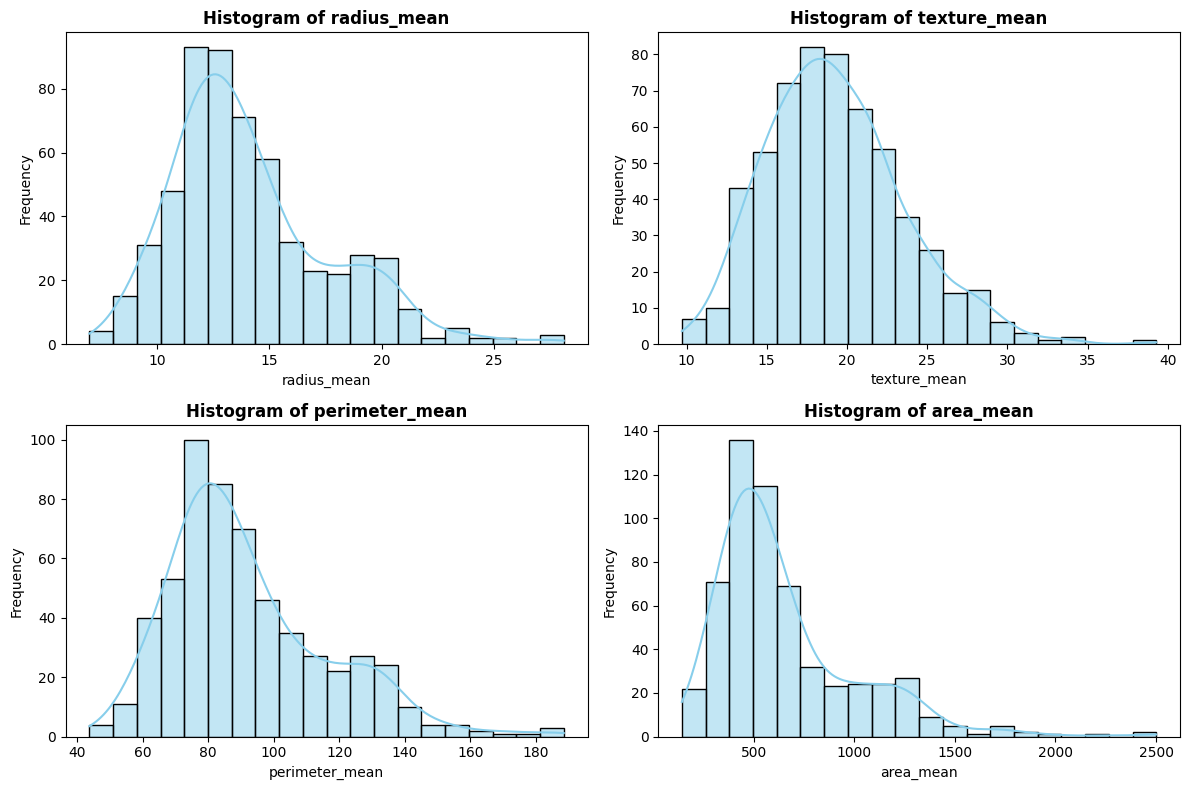

In [ ]:
# Histograms
features = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean']

# 3. Create a 2x2 subplot layout
plt.figure(figsize=(12, 8))

for i, col in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.histplot(data[col], kde=True, color='skyblue', edgecolor='black', bins=20)
    plt.title(f'Histogram of {col}', fontsize=12, fontweight='bold')
    plt.xlabel(col, fontsize=10)
    plt.ylabel('Frequency', fontsize=10)

plt.tight_layout()
plt.show()


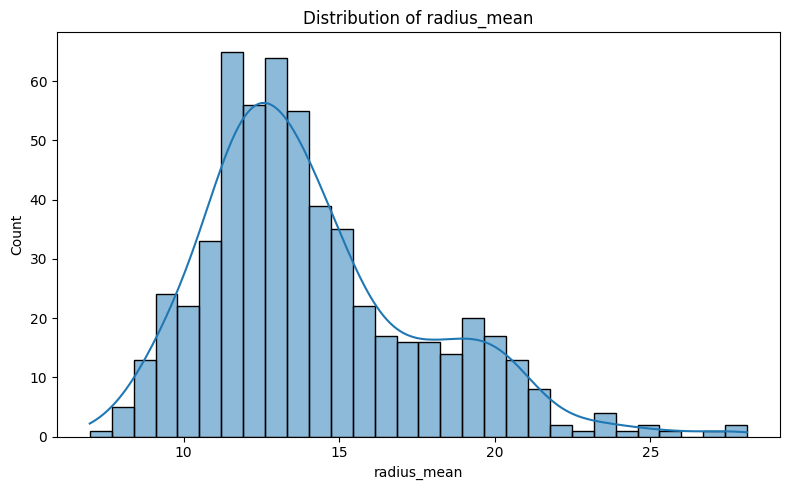

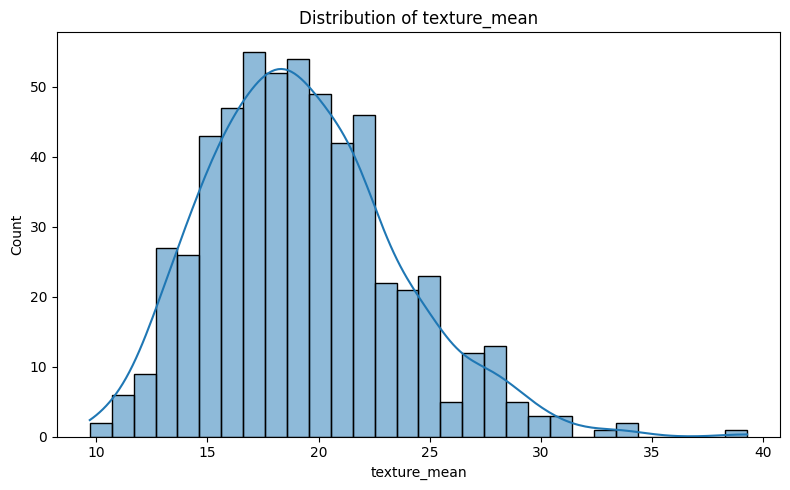

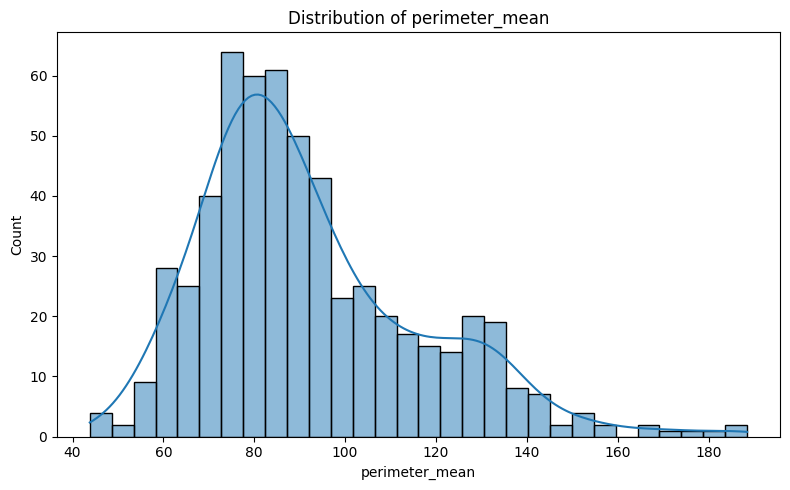

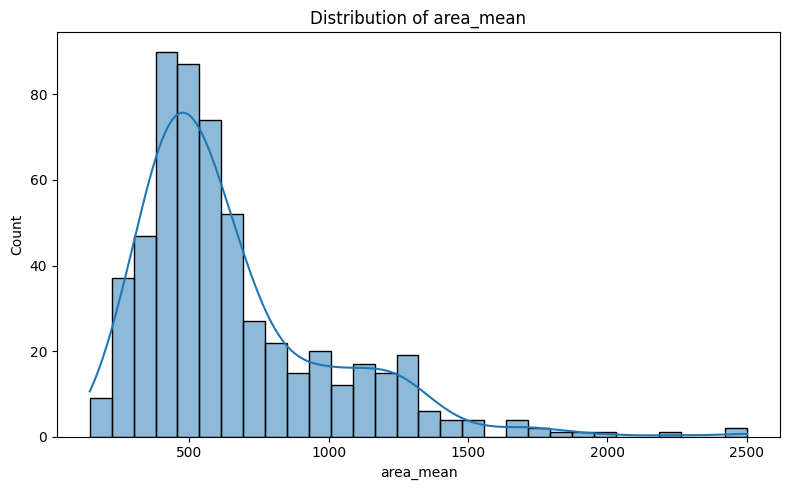

In [ ]:
# Bar graphs
for col in nume_cols[:4]:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=data, x=col, bins=30, kde=True)   # bins group the values

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()


<Axes: xlabel='radius_mean', ylabel='diagnosis'>

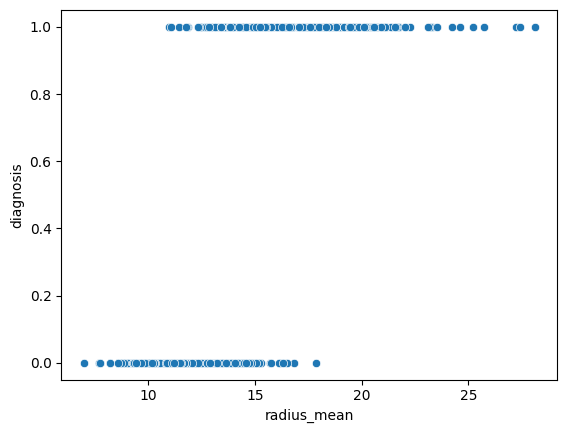

In [ ]:
# Scatterplots
sns.scatterplot(data=data,x = 'radius_mean',y = 'diagnosis')

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  77,
  78,
  79,
  80,
  81,
  82,
  83,
  84,
  85,
  86,
  87,
  88,
  89,
  90,
  91,
  92,
  93,
  94,
  95,
  96,
  97,
  98,
  99,
  100,
  101,
  102,
  103,
  104,
  105,
  106,
  107,
  108,
  109,
  110,
  111,
  112,
  113,
  114,
  115,
  116,
  117,
  118,
  119,
  120,
  121,
  122,
  123,
  124,
  125,
  126,
  127,
  128,
  129,
  130,
  131,
  132,
  133,
  134,
  135,
  136,
  137,
  138,
  139,
  140,
  141,
  142,
  143,
  144,
  145,
  146,
  147,
  148,
  149,
  150,
  151,
  152,
  153,
  154,
  155,
  156,
  157,
  15

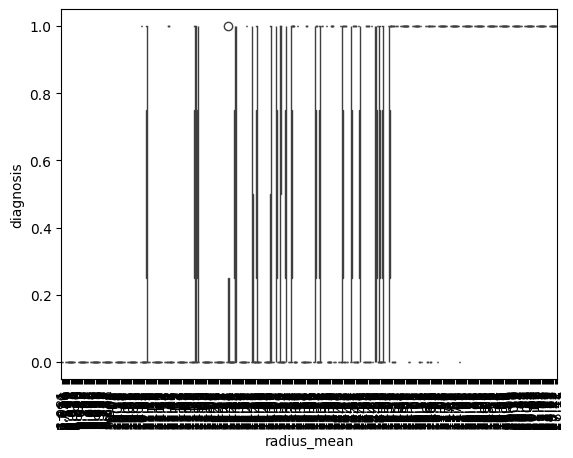

In [ ]:
# Boxplots
sns.boxplot(data = data,x = 'radius_mean',y = 'diagnosis')
plt.xticks(rotation=90)

#*data['diagnosis_label'] = data['diagnosis'].map({0: 'Benign', 1: 'Malignant'})

#plt.figure(figsize=(6, 5))
#sns.boxplot(data=data, x='diagnosis_label', y='radius_mean')
#plt.title('Radius Mean by Diagnosis')
#plt.xlabel('Diagnosis')
#plt.ylabel('Mean Radius')
#plt.show()



<Axes: xlabel='radius_mean', ylabel='diagnosis'>

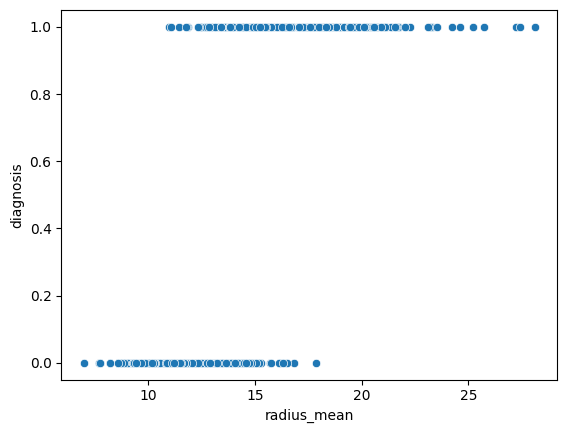

In [ ]:
# Pie charts
sns.scatterplot(data=data,x = 'radius_mean',y = 'diagnosis')

<Axes: >

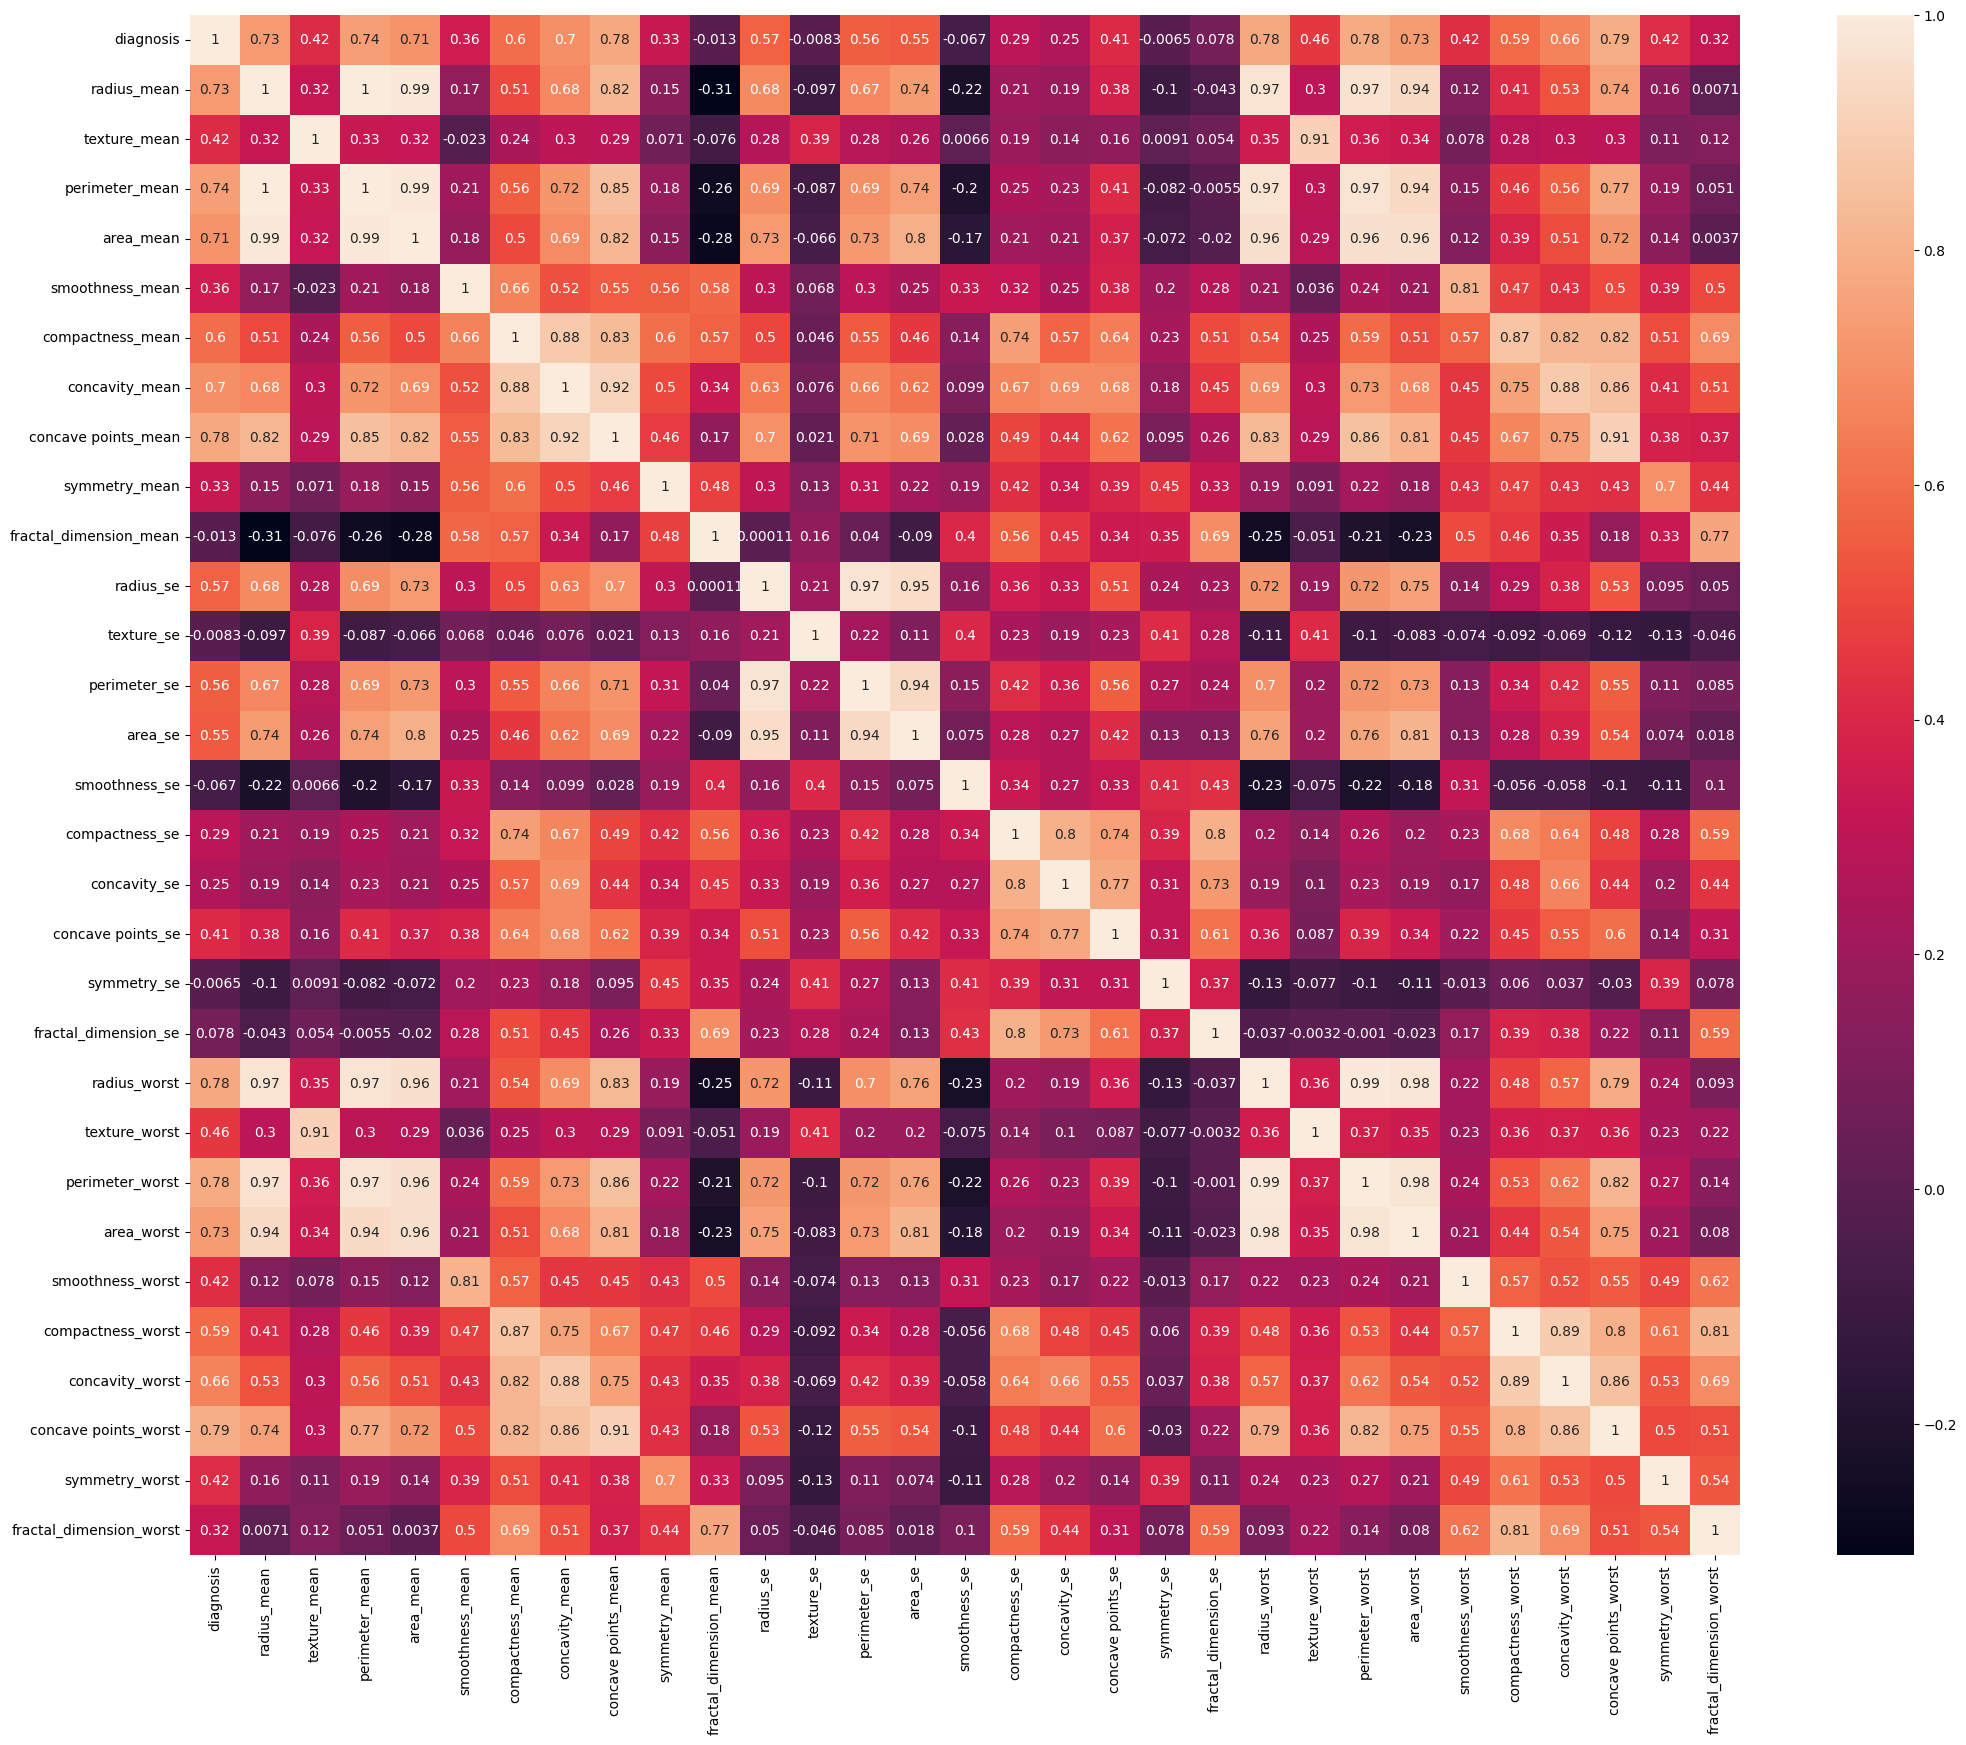

In [ ]:
# Correlation heatmaps
plt.figure(figsize=(25, 20))
sns.heatmap(data.corr(numeric_only = True),annot =True)


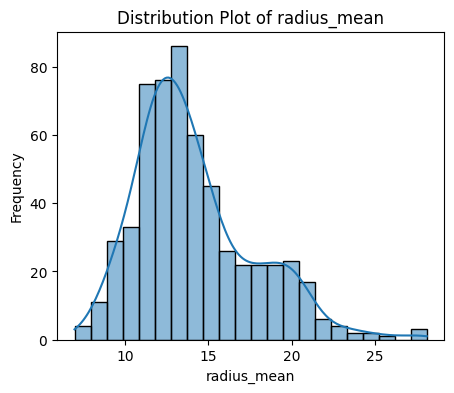

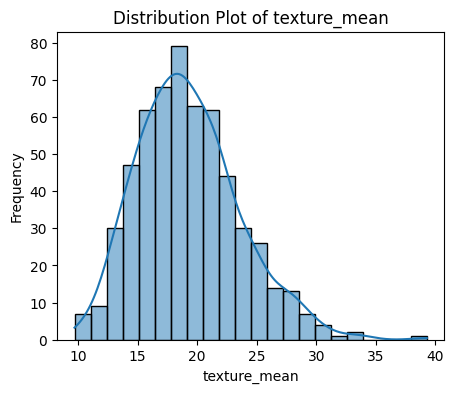

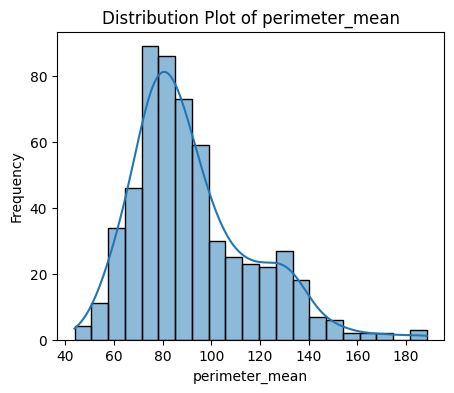

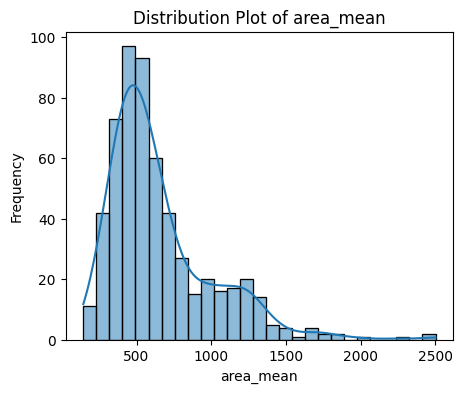

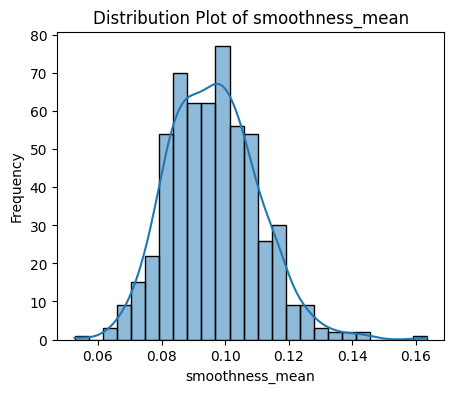

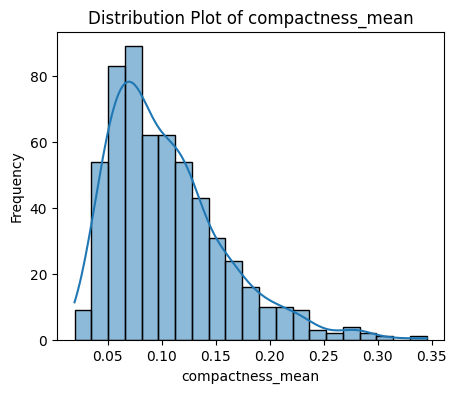

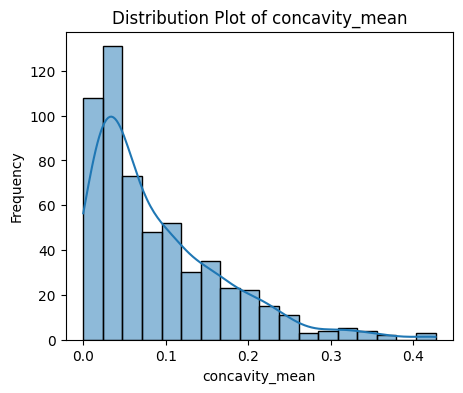

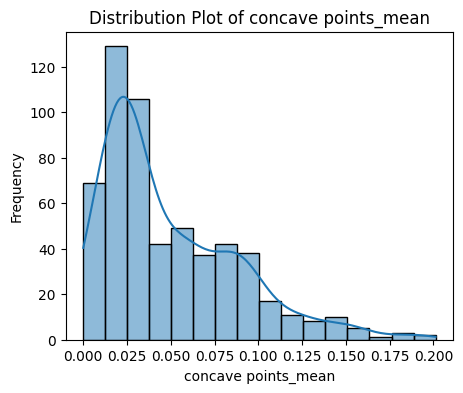

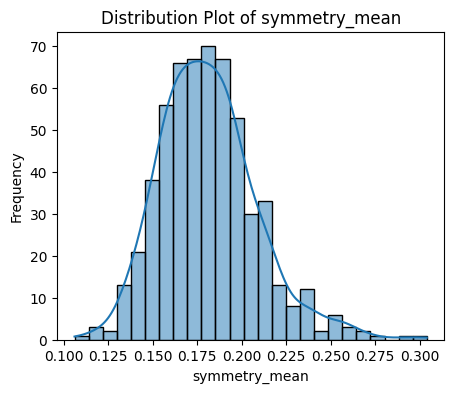

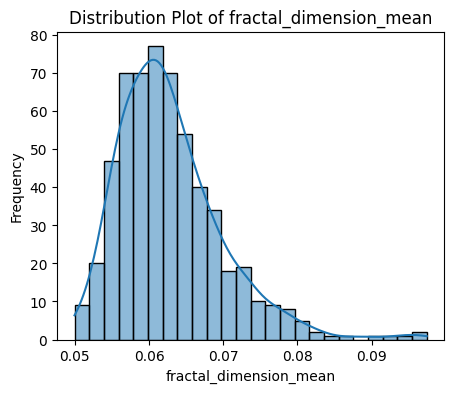

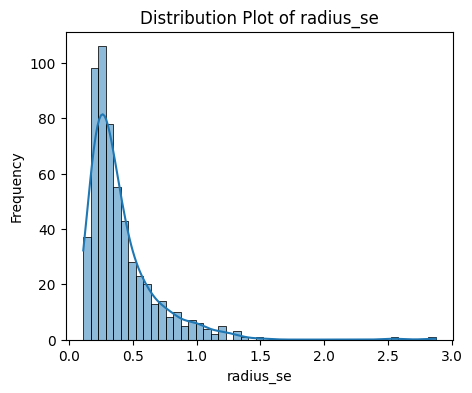

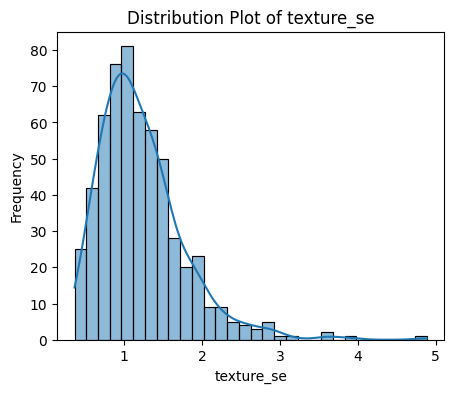

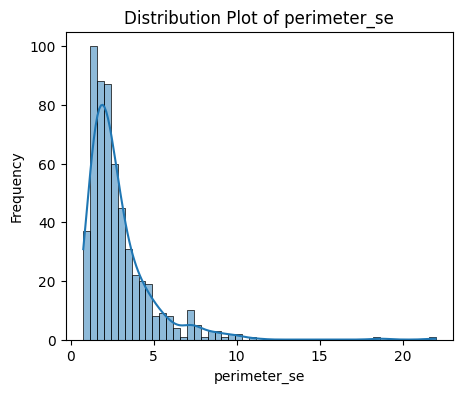

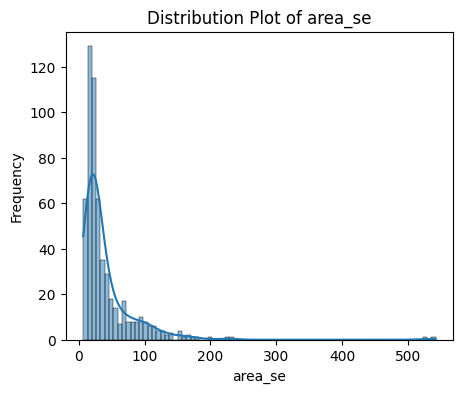

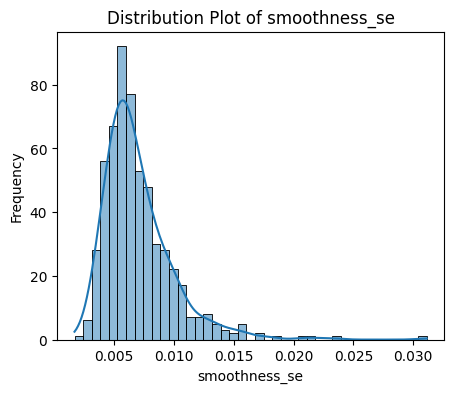

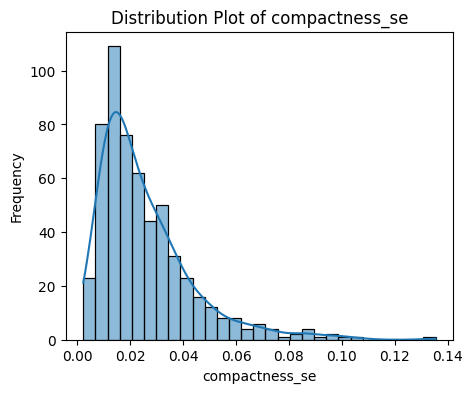

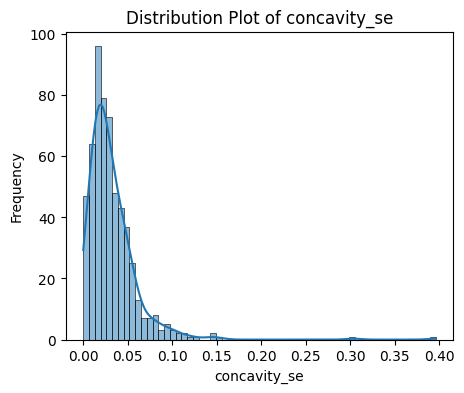

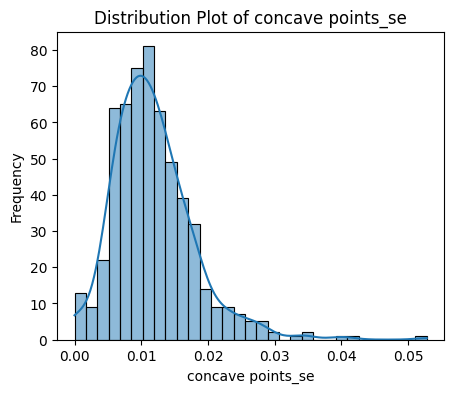

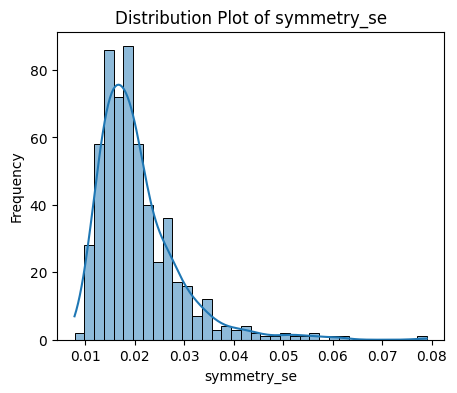

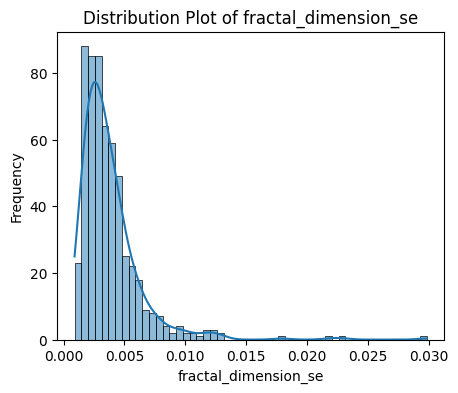

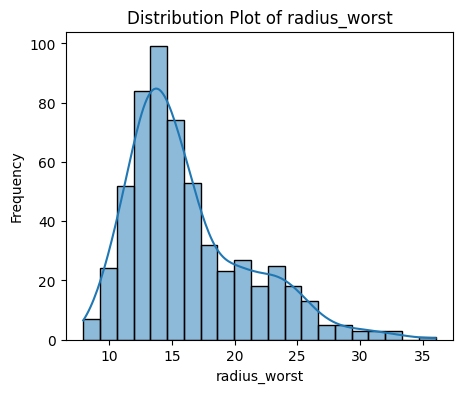

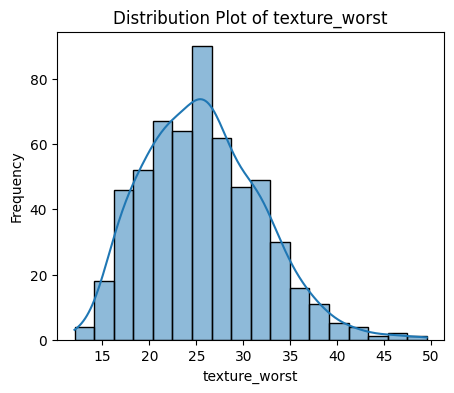

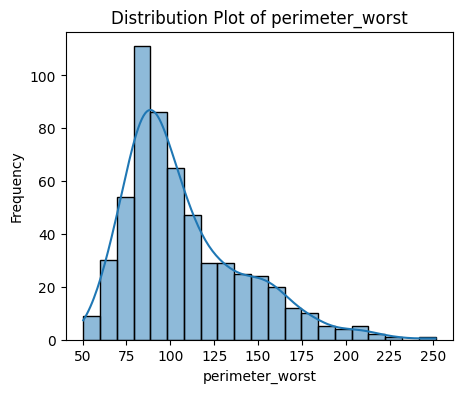

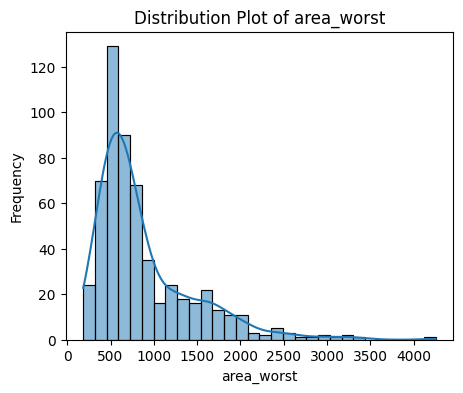

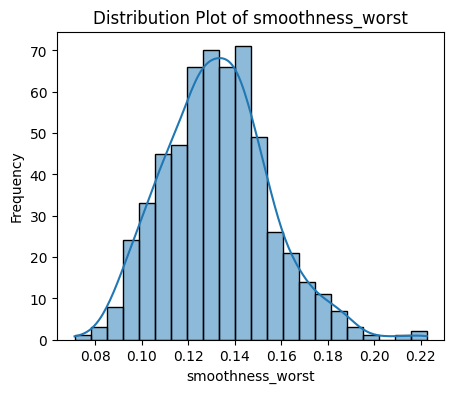

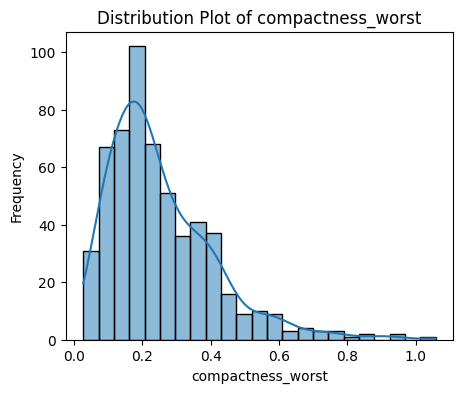

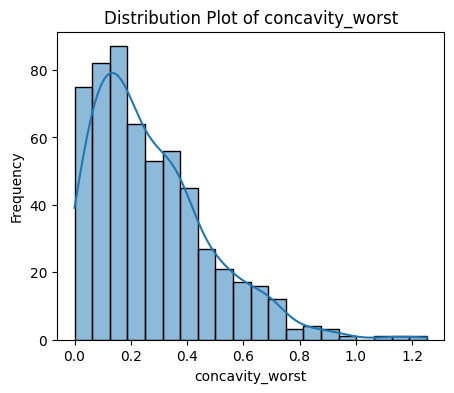

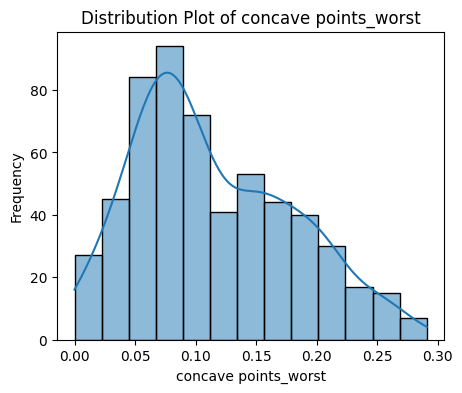

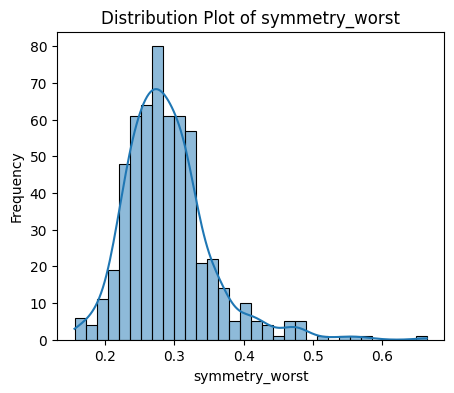

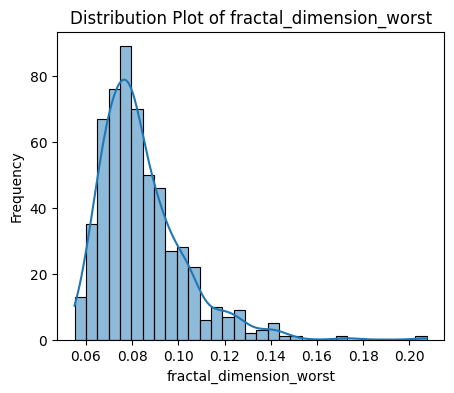

In [ ]:
# Distribution plots
# Select numerical columns
#numeric_columns = data.select_dtypes(include=['int64', 'float64']).columns

# Plot the distribution of each numerical feature
for col in nume_cols:
    plt.figure(figsize=(5, 4))
    sns.histplot(data=data, x=col, kde=True)
    plt.title(f'Distribution Plot of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

In [ ]:
# Pair plots

In [ ]:
# Cluster

In [ ]:
# visualizations

In [ ]:
# Dendrograms

D. Statistical Analysis

In [ ]:
# Range
range_tbl = pd.DataFrame({
    'Feature': features,
    'Range': [data[c].max() - data[c].min() for c in features]
}).round(4)

display(range_tbl)

,Feature,Range
0,radius_mean,21.129
1,texture_mean,29.570
2,perimeter_mean,144.710
3,area_mean,2357.500


In [ ]:
# Interquartile Range (IQR)
iqr_tbl = pd.DataFrame({
    'Feature': features,
    'IQR': [data[c].quantile(0.75) - data[c].quantile(0.25)
            for c in features]
}).round(4)

display(iqr_tbl)

,Feature,IQR
0,radius_mean,4.08
1,texture_mean,5.63
2,perimeter_mean,28.93
3,area_mean,362.40


In [ ]:
# Mean Absolute Deviation (MAD)
mad_tbl = pd.DataFrame({
    'Feature': features,
    'MAD': [(data[c] - data[c].mean()).abs().mean()
            for c in features]
}).round(4)

display(mad_tbl)

,Feature,MAD
0,radius_mean,2.7519
1,texture_mean,3.3850
2,perimeter_mean,19.0326
3,area_mean,263.4834


In [ ]:
# Variance
variance_tbl = pd.DataFrame({
    'Feature': features,
    'Variance': [data[c].var() for c in features]
}).round(4)

display(variance_tbl)

,Feature,Variance
0,radius_mean,12.4189
1,texture_mean,18.4989
2,perimeter_mean,590.4405
3,area_mean,123843.5543


In [ ]:
# Standard Deviation
std_tbl = pd.DataFrame({
    'Feature': features,
    'Standard Deviation': [data[c].std() for c in features]
}).round(4)

display(std_tbl)

,Feature,Standard Deviation
0,radius_mean,3.5240
1,texture_mean,4.3010
2,perimeter_mean,24.2990
3,area_mean,351.9141


In [ ]:
# Pearson Correlation Coefficient (PCC)
pcc_tbl = pd.DataFrame({
    'Feature': features,
    'PCC': [data[c].corr(y) for c in features]
}).round(4)

display(pcc_tbl)

,Feature,PCC
0,radius_mean,0.7300
1,texture_mean,0.4152
2,perimeter_mean,0.7426
3,area_mean,0.7090


Outlier Detection

In [ ]:
# IQR method
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

iqr_outliers = (X < lower_bound) | (X > upper_bound)

iqr_out = iqr_outliers.sum().to_frame(name='IQR Outliers')

display(iqr_out.sort_values('IQR Outliers', ascending=False).head(10))

,IQR Outliers
area_se,65
radius_se,38
perimeter_se,38
area_worst,35
smoothness_se,30
fractal_dimension_se,28
compactness_se,28
symmetry_se,27
area_mean,25
fractal_dimension_worst,24


In [ ]:
# Z-score
z = (X - X.mean()) / X.std(ddof=0)

z_outliers = z.abs() > 3

z_out = z_outliers.sum().to_frame(name='Z-score Outliers')

display(z_out.sort_values('Z-score Outliers', ascending=False).head(10))

print(
    'Patients with at least one |z| > 3 value:',
    int(z_outliers.any(axis=1).sum()),
    'of',
    len(data)
)

,Z-score Outliers
compactness_se,12
symmetry_se,11
area_worst,10
fractal_dimension_se,10
compactness_worst,10
compactness_mean,9
texture_se,9
fractal_dimension_worst,9
symmetry_worst,9
concavity_mean,9


Patients with at least one |z| > 3 value: 74 of 569


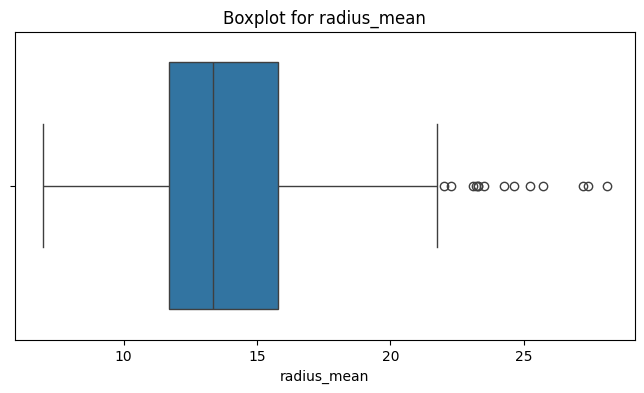

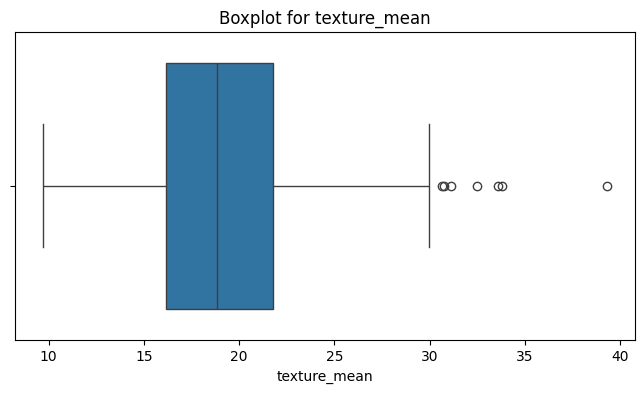

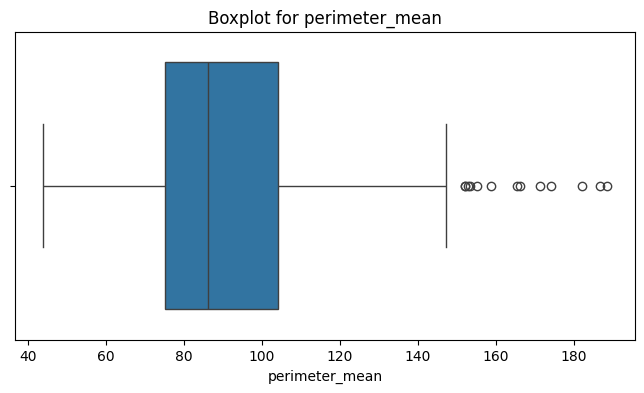

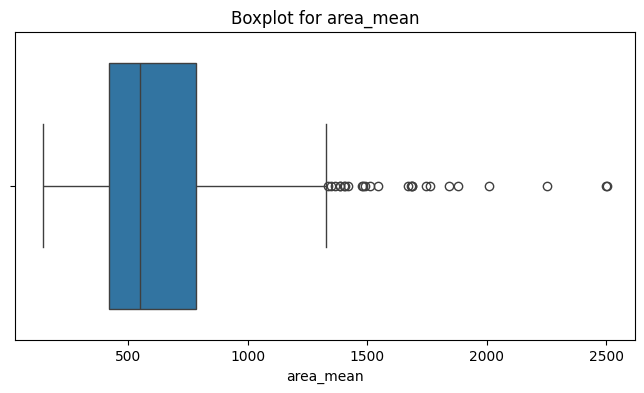

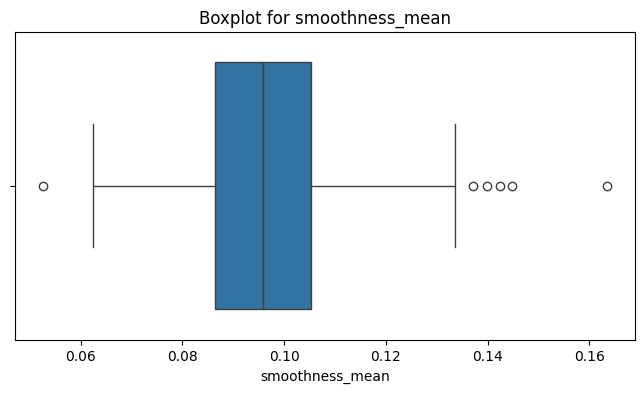

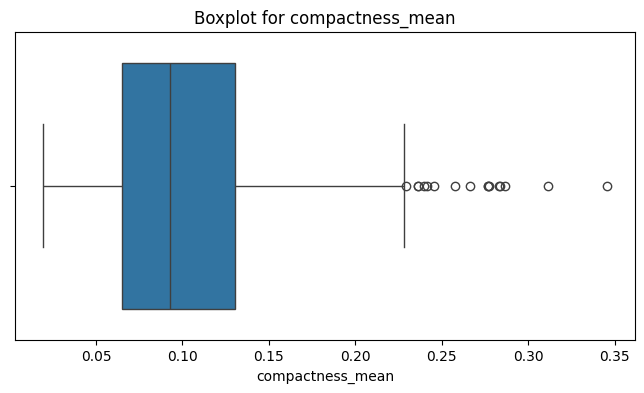

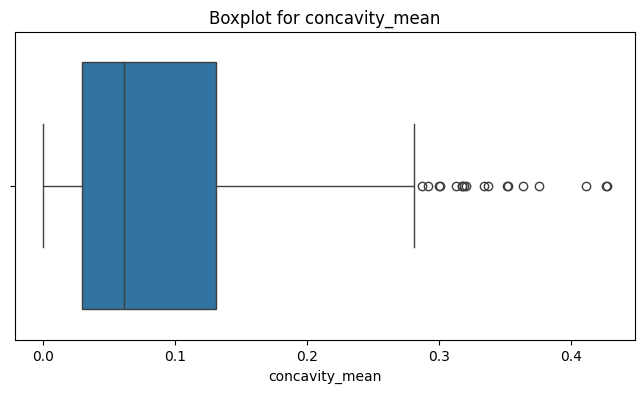

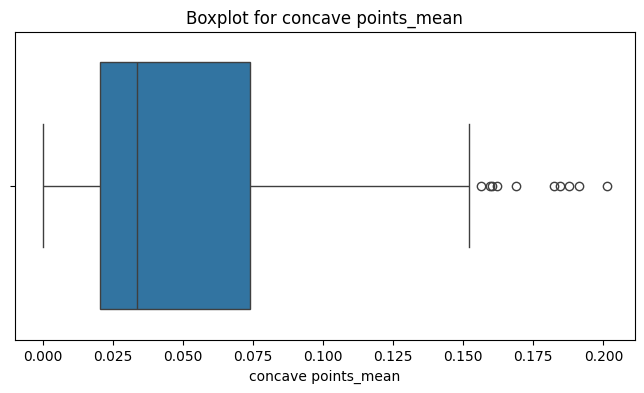

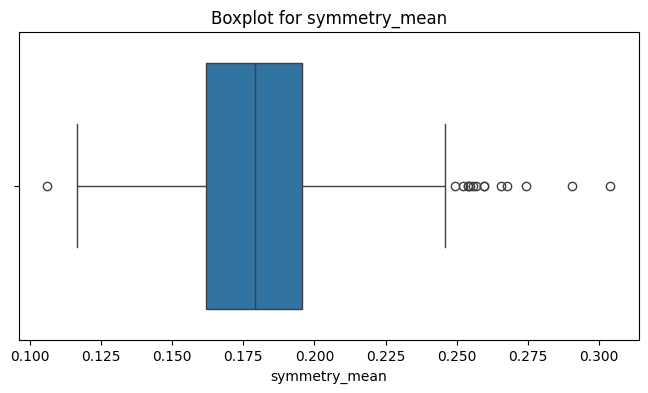

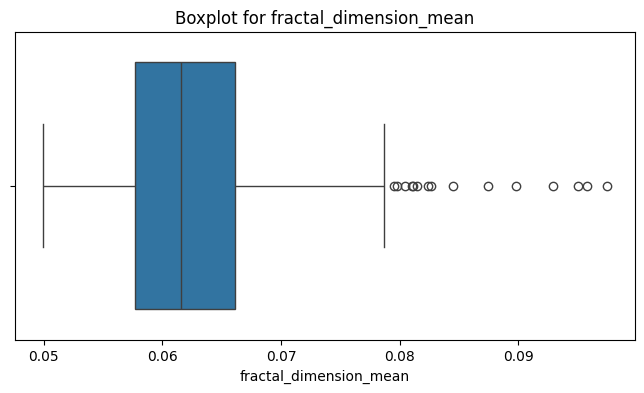

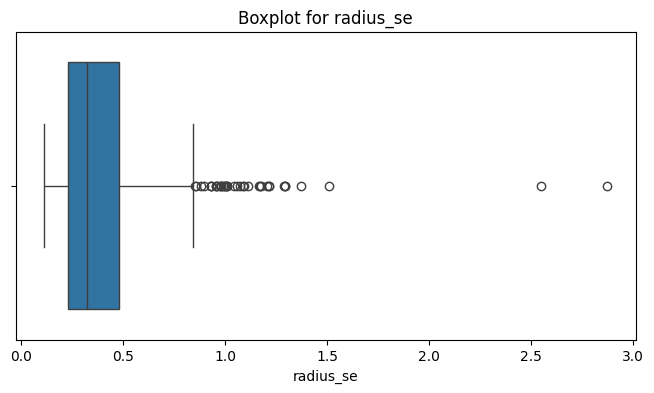

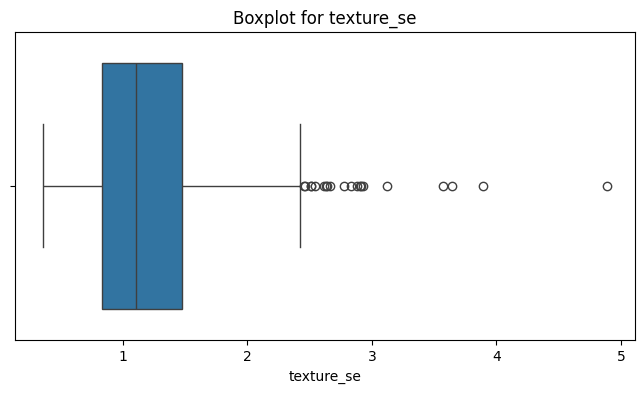

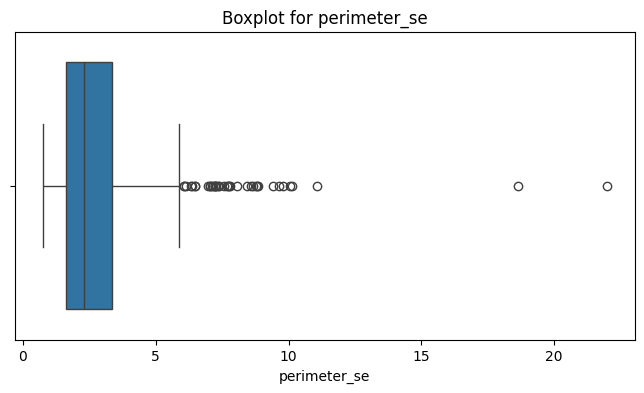

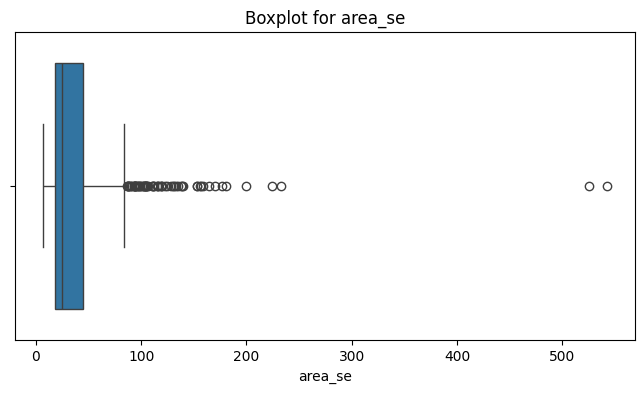

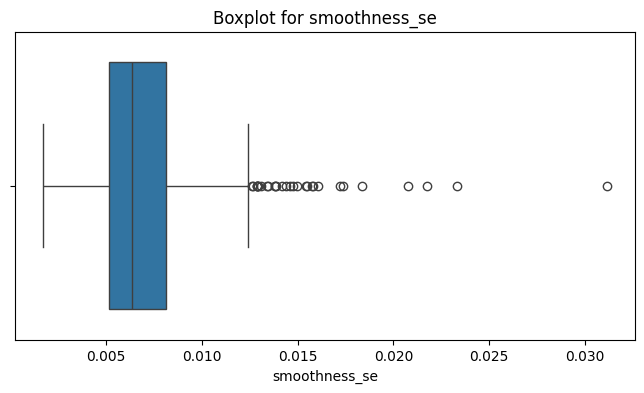

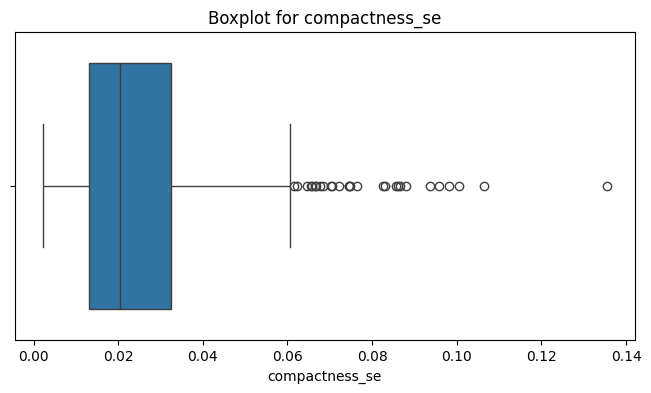

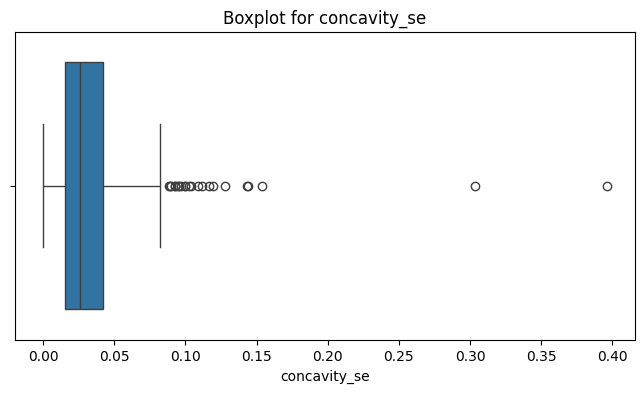

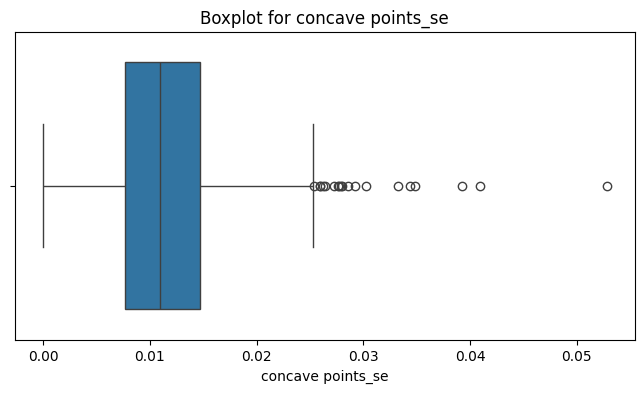

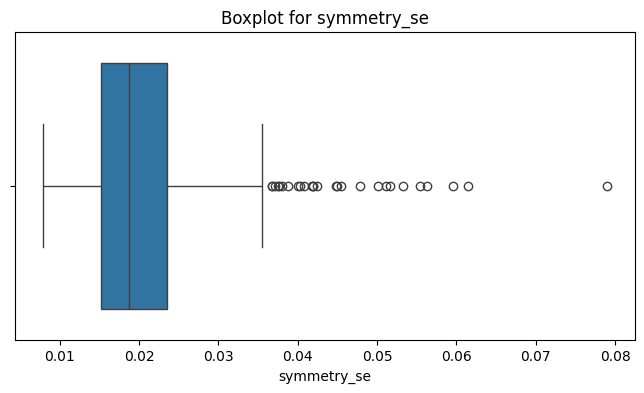

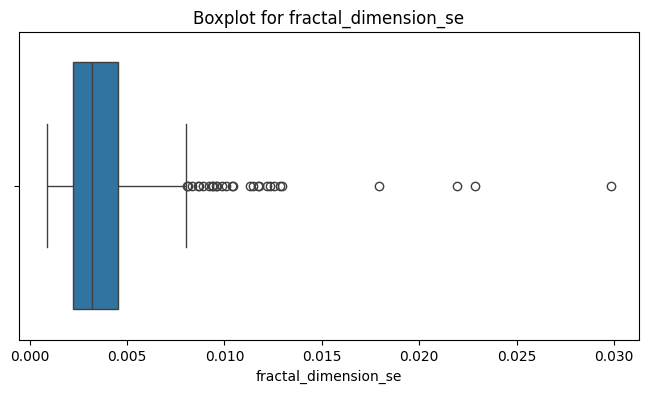

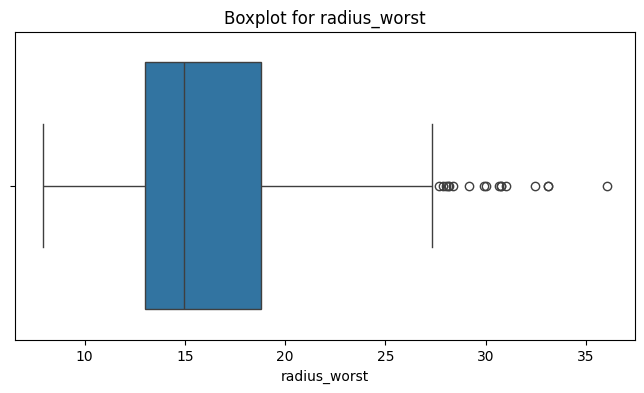

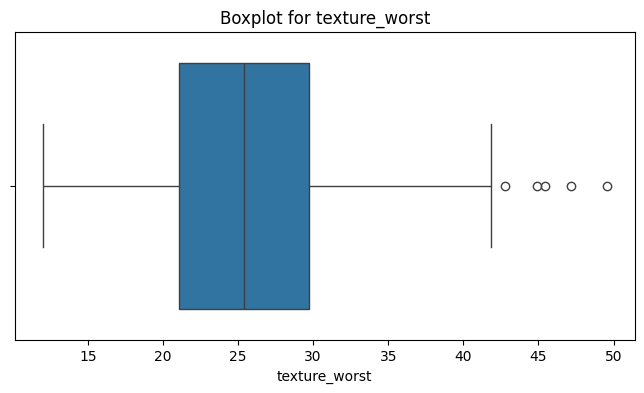

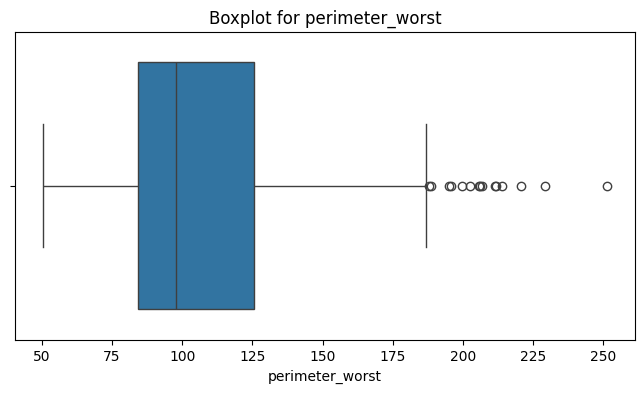

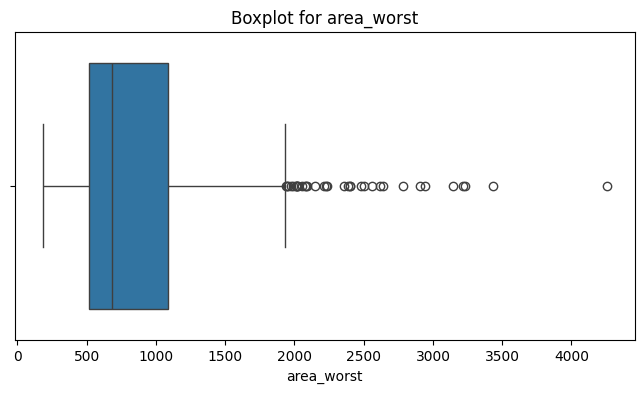

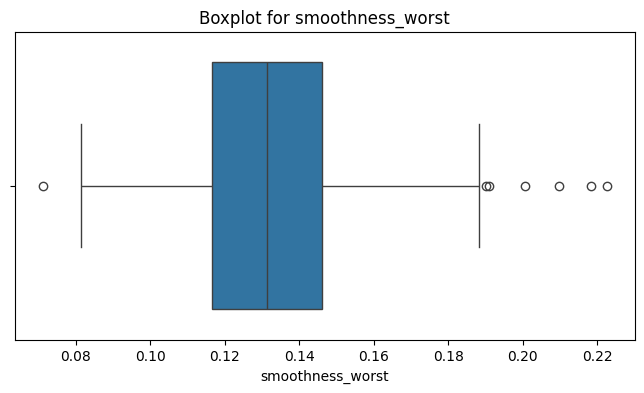

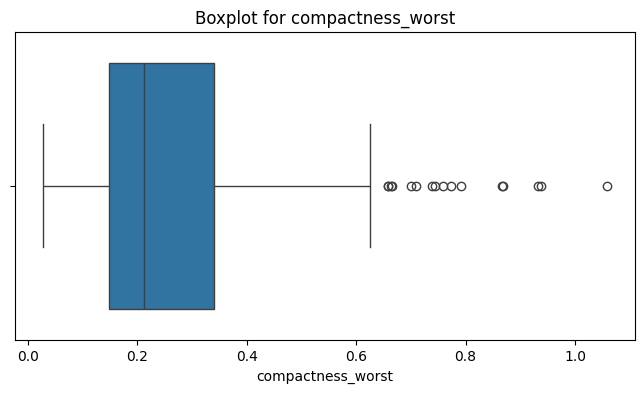

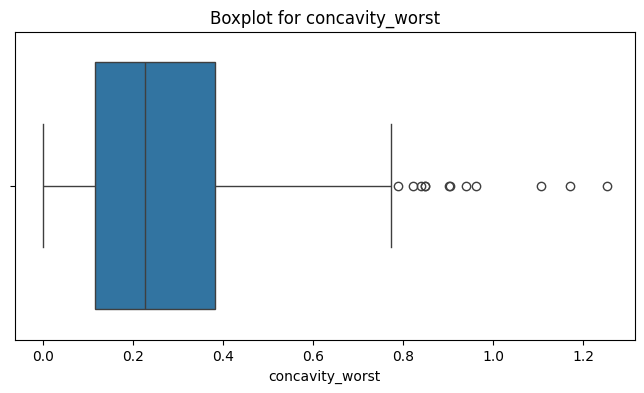

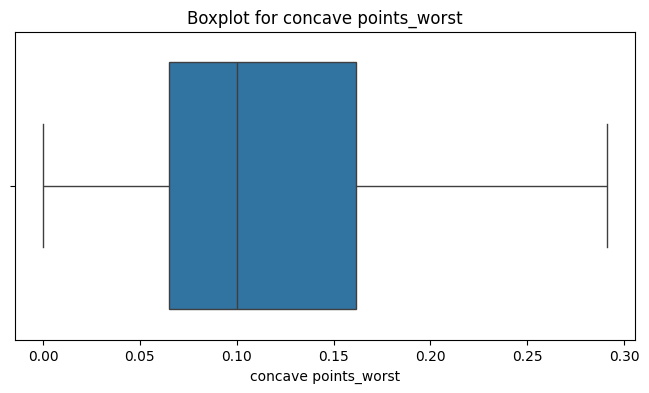

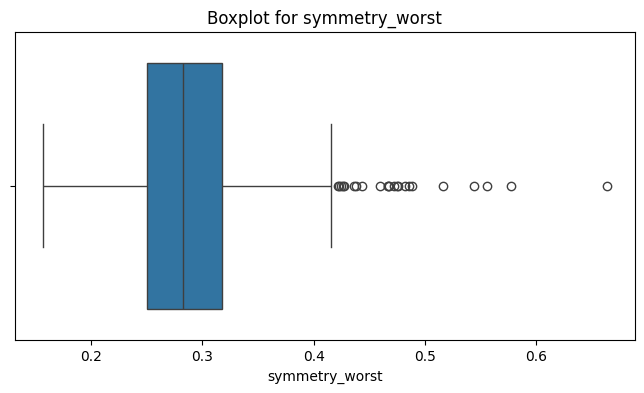

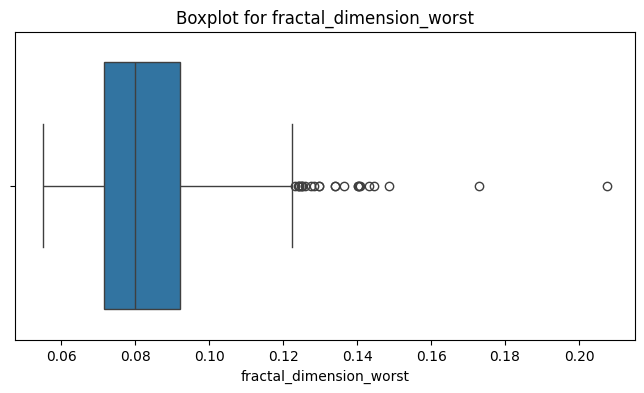

In [ ]:
# Boxplots
# Boxplot for each numeric feature
for c in X.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=X[c])
    plt.title(f'Boxplot for {c}')
    plt.xlabel(c)
    plt.show()

E. Model Training

In [ ]:
X_scaled

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,...,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,...,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,2.110995,0.721473,2.060786,2.343856,1.041842,0.219060,1.947285,2.320965,-0.312589,-0.931027,...,1.901185,0.117700,1.752563,2.015301,0.378365,-0.273318,0.664512,1.629151,-1.360158,-0.709091
565,1.704854,2.085134,1.615931,1.723842,0.102458,-0.017833,0.693043,1.263669,-0.217664,-1.058611,...,1.536720,2.047399,1.421940,1.494959,-0.691230,-0.394820,0.236573,0.733827,-0.531855,-0.973978
566,0.702284,2.045574,0.672676,0.577953,-0.840484,-0.038680,0.046588,0.105777,-0.809117,-0.895587,...,0.561361,1.374854,0.579001,0.427906,-0.809587,0.350735,0.326767,0.414069,-1.104549,-0.318409
567,1.838341,2.336457,1.982524,1.735218,1.525767,3.272144,3.296944,2.658866,2.137194,1.043695,...,1.961239,2.237926,2.303601,1.653171,1.430427,3.904848,3.197605,2.289985,1.919083,2.219635


In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separate features and target
X = data.drop(columns=['diagnosis'])
y = data['diagnosis']

# 2. Split into training (70%) and temporary (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. Split temporary into validation (15%) and test (15%)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# 4. Scale the features
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_valid_scaled = pd.DataFrame(
    scaler.transform(X_valid),
    columns=X_valid.columns,
    index=X_valid.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)


# 6. Convert diagnosis labels to binary values
# For the Breast Cancer Wisconsin dataset: B = 0, M = 1
y_train_binary = (y_train == 'M').astype('float32')
y_valid_binary = (y_valid == 'M').astype('float32')
y_test_binary = (y_test == 'M').astype('float32')

# 7. Display the results
print(X_train_scaled.head())
print("Training:", X_train_scaled.shape)
print("Validation:", X_valid_scaled.shape)
print("Testing:", X_test_scaled.shape)



     radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
78      1.705820      1.049745        2.121295   1.669337         2.276458   
330     0.536388     -0.909945        0.569095   0.390316        -0.065868   
378    -0.131456     -0.993336       -0.148848  -0.211543        -0.916169   
213     0.928077      1.418055        0.925405   0.828546         0.329734   
89      0.144699     -0.972488        0.158315  -0.009697         1.205760   

     compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
78           4.544295        3.539139             2.848393       4.032390   
330          0.644945        0.393543             0.557002      -0.116781   
378         -0.508574       -0.567530            -0.606645      -0.079867   
213          0.223748        0.983188             0.443947      -1.866520   
89           0.585041        0.137701             0.562858       1.116158   

     fractal_dimension_mean  ...  radius_worst  texture_worst  \
78 

In [ ]:
# Train the assigned machine-learning model.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.optimizers import Adam

# Create Logistic Regression model
model_1 = Sequential([
    Dense(
        units=1,
        activation="sigmoid",
        input_shape=(X_train_scaled.shape[1],)
    )
])

In [ ]:
# Compile the model
model_1.compile(
    loss=BinaryCrossentropy(),
    optimizer=Adam(),
    metrics=["accuracy"]
)

In [ ]:
# Train the model
history = model_1.fit(
    X_train_scaled,
    y_train_binary,
    validation_data=(X_valid_scaled, y_valid_binary),
    epochs=100,
    batch_size=32
)


Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5251 - loss: 0.9047 - val_accuracy: 0.4235 - val_loss: 0.9390
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5251 - loss: 0.8733 - val_accuracy: 0.4118 - val_loss: 0.9099
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5226 - loss: 0.8435 - val_accuracy: 0.4235 - val_loss: 0.8842
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5201 - loss: 0.8194 - val_accuracy: 0.4353 - val_loss: 0.8618
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5101 - loss: 0.7982 - val_accuracy: 0.4353 - val_loss: 0.8415
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5302 - loss: 0.7794 - val_accuracy: 0.4471 - val_loss: 0.8232
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5276 - loss: 0.7640 - val_accuracy: 0.4471 - val_loss: 0.8056
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5251 - loss: 0.7493 - val_accuracy: 0.4353 - 

In [ ]:
# Evaluate the trained model on test data
test_loss, test_accuracy = model_1.evaluate(
    X_test_scaled,
    y_test_binary,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.2881
Test Loss: 0.2880649268627167
Test Accuracy: 1.0
Test Accuracy (%): 100.0


In [ ]:
# Predict probabilities
y_pred_prob = model_1.predict(X_test_scaled)

# Convert probabilities into binary predictions
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()
y_true = y_test_binary.to_numpy().astype(int)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=['Benign', 'Malignant'],
    zero_division=0
))


              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00        86
   Malignant       0.00      0.00      0.00         0

    accuracy                           1.00        86
   macro avg       0.50      0.50      0.50        86
weighted avg       1.00      1.00      1.00        86



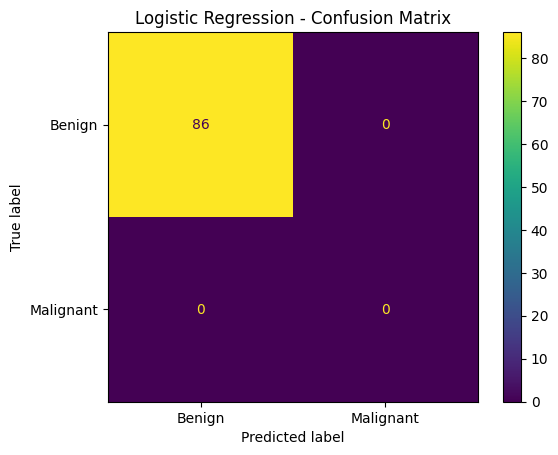

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Benign', 'Malignant']
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


In [ ]:
# Explain the selected model and its working principle.

In [ ]:
# Where appropriate, tune important hyperparameters.

G. Training/Evaluation Curves

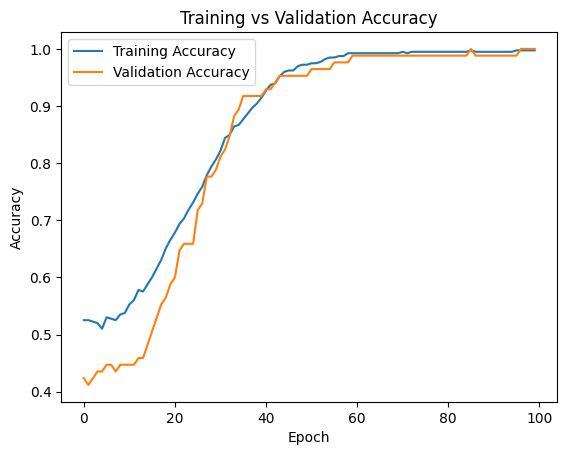

In [ ]:
# Training vs. validation accuracy

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.show()


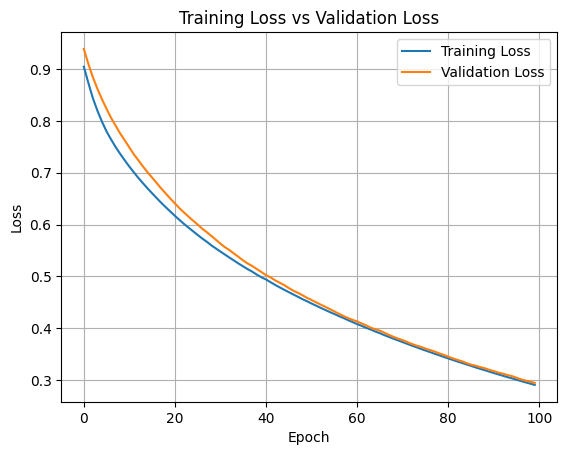

In [ ]:
# Training vs. validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
First 20 residuals:
[-0.33863324 -0.28880402 -0.2860341  -0.1963812  -0.19438384 -0.24514824
 -0.28106874 -0.24601392 -0.27140096 -0.27858597 -0.23514228 -0.34486014
 -0.2646058  -0.2389366  -0.29378566 -0.25360098 -0.19592051 -0.26493803
 -0.1446411  -0.23207459]


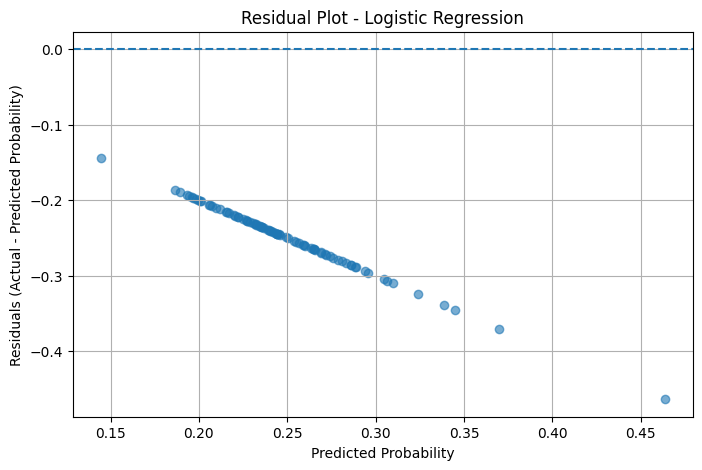

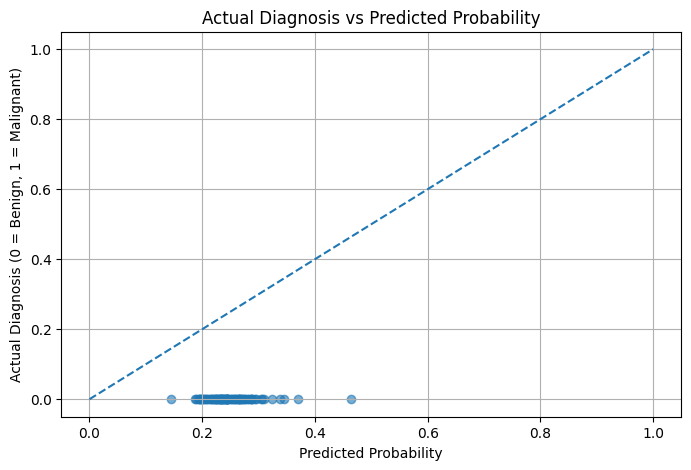

In [ ]:
# Error/residual plots
#Predicted leble
y_pred_prob = model_1.predict(X_test_scaled).ravel()

#Actual leble
y_actual = y_test_binary.to_numpy()

# Calculate residuals
residuals = y_actual - y_pred_prob

print("First 20 residuals:")
print(residuals[:20])


plt.figure(figsize=(8, 5))
plt.scatter(y_pred_prob, residuals, alpha=0.6)
plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Probability")
plt.ylabel("Residuals (Actual - Predicted Probability)")
plt.title("Residual Plot - Logistic Regression")
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))
plt.scatter(y_pred_prob, y_actual, alpha=0.6)
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("Predicted Probability")
plt.ylabel("Actual Diagnosis (0 = Benign, 1 = Malignant)")
plt.title("Actual Diagnosis vs Predicted Probability")
plt.grid(True)
plt.show()




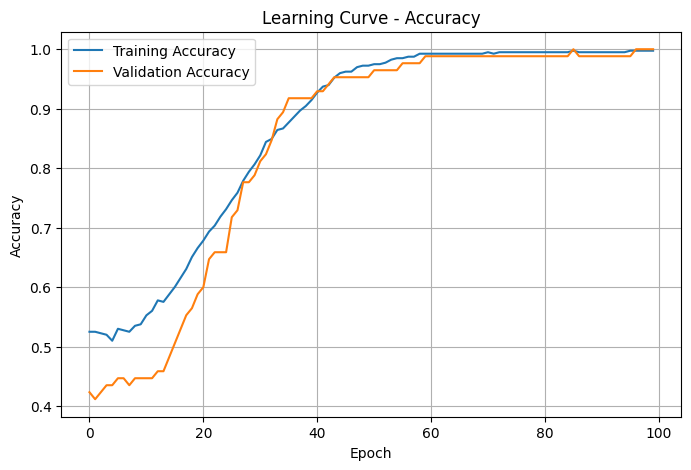

In [ ]:
# Learning curves
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Learning Curve - Accuracy')
plt.legend()
plt.grid(True)
plt.show()


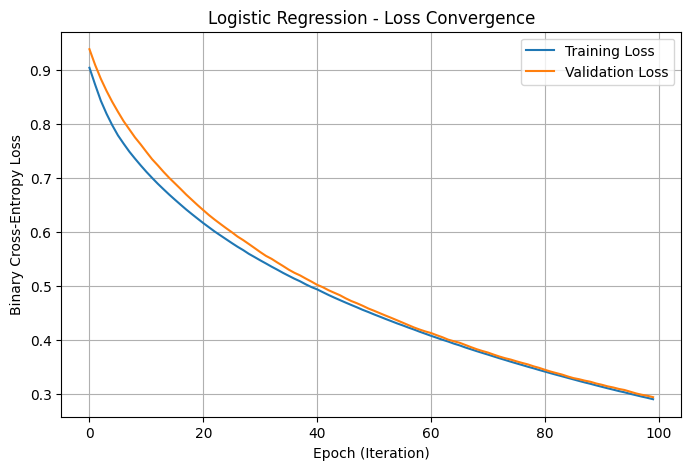

In [ ]:
# Iteration/convergence plots
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch (Iteration)')
plt.ylabel('Binary Cross-Entropy Loss')
plt.title('Logistic Regression - Loss Convergence')
plt.legend()
plt.grid(True)
plt.show()
